# Stats 161 Midterm Project

## Data import

We select **24 consecutive weeks of Polymarket data, from January 1 to June 17, 2026**, to study wallet trading behavior. All dates and timestamps use UTC.


### 1. Setup


In [1]:
import pandas as pd
import requests

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from io import BytesIO


### 2. Dates and access settings


In [2]:
start_date = "2026-01-01"
end_date = "2026-06-17"
dates = pd.date_range(start_date, end_date, freq="D", tz="UTC")

base_url = "https://d1yyqbluk0oz0t.cloudfront.net"
course_password = 'PolymarketData2026!'


### 3. Wallet trades

We combine the 168 daily trade files into `wallet_trades`, keeping all wallets and all eight original variables. Each row is a recorded fill; one order may produce multiple fills.

| Variable | Description |
|---|---|
| `wallet` | Pseudonymous wallet ID, consistent across daily files. |
| `market` | Market slug; links to `markets.slug`. |
| `time` | Fill timestamp in UTC. |
| `side` | BUY or SELL for the recorded wallet. |
| `outcome` | Traded outcome, such as Yes, No, Up, Down, or a team name. |
| `price` | Execution price per share. |
| `size` | Number of shares traded. |
| `dollars` | Recorded dollar value of the fill. |


In [3]:
session = requests.Session()
session.auth = ("polymarketdatabase", course_password)
daily_trades = []

for day in dates:
    date_string = day.strftime("%Y-%m-%d")
    url = f"{base_url}/wallet_trades/trades-{date_string}.parquet"

    response = session.get(url, timeout=120)
    response.raise_for_status()
    day_trades = pd.read_parquet(BytesIO(response.content), dtype_backend="pyarrow")
    day_trades["time"] = pd.to_datetime(day_trades["time"], utc=True)

    # Check the file date.
    assert len(day_trades) > 0, f"Empty file: {date_string}"
    assert day_trades["time"].min().date() == day.date(), f"Unexpected date: {date_string}"
    assert day_trades["time"].max().date() == day.date(), f"Unexpected date: {date_string}"

    daily_trades.append(day_trades)
    if len(daily_trades) % 28 == 0:
        print(f"Loaded {len(daily_trades)} of {len(dates)} daily files.")

wallet_trades = pd.concat(daily_trades, ignore_index=True)
session.close()
del daily_trades, day_trades, response

print(f"Wallet trades imported: {len(wallet_trades):,} rows.")


Loaded 28 of 168 daily files.
Loaded 56 of 168 daily files.
Loaded 84 of 168 daily files.
Loaded 112 of 168 daily files.
Loaded 140 of 168 daily files.
Loaded 168 of 168 daily files.
Wallet trades imported: 56,738,552 rows.


### 4. Related market data

We import market, event, and settlement records for the markets in `wallet_trades`. All original columns are retained; key variables are listed below.

| DataFrame | Content | Key variables |
|---|---|---|
| `markets` | Market questions, outcome labels, and parent events. | `slug`, `title`, `event_slug`, `condition_id`, `outcomes`, `token_ids`, `start_date`, `end_date` |
| `events` | Event titles, descriptions, and scheduled dates. | `slug`, `title`, `description`, `start_date`, `end_date` |
| `resolutions` | Available settlement records. | `market_slug`, `resolved_yes`, `price_at_close`, `resolved_at` |

**Links:** `wallet_trades.market` → `markets.slug`; `markets.event_slug` → `events.slug`; `resolutions.market_slug` → `markets.slug`.

Market prices and volumes in the metadata reflect the current stored snapshot. Interpret resolution labels using the market's actual outcome labels.


In [4]:
database_url = URL.create(
    "postgresql+psycopg2",
    username="polymarketdatabase.merbqatlxbrcvtbnuaqe",
    password=course_password,
    host="aws-0-us-west-2.pooler.supabase.com",
    port=6543,
    database="postgres",
)

engine = create_engine(
    database_url,
    connect_args={"sslmode": "require", "connect_timeout": 20},
    execution_options={"postgresql_readonly": True},
)

market_slugs = wallet_trades["market"].dropna().unique().tolist()

with engine.connect() as connection:
    markets = pd.read_sql_query(
        text("SELECT * FROM public.markets WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )
    resolutions = pd.read_sql_query(
        text("SELECT * FROM public.resolutions WHERE market_slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )


In [5]:
event_slugs = markets["event_slug"].dropna().unique().tolist()

with engine.connect() as connection:
    events = pd.read_sql_query(
        text("SELECT * FROM public.events WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": event_slugs},
    )

engine.dispose()


### 5. Import check

Confirm the row and column counts, and report traded markets without matching catalog metadata.


In [6]:
for name, data in [("wallet_trades", wallet_trades), ("markets", markets),
                   ("events", events), ("resolutions", resolutions)]:
    print(f"{name}: {len(data):,} rows, {len(data.columns)} columns")

missing_market_slugs = set(market_slugs) - set(markets["slug"])
print(f"Traded market slugs without catalog metadata: {len(missing_market_slugs):,}")
print(f"Study period: {start_date} through {end_date} (UTC)")


wallet_trades: 56,738,552 rows, 8 columns
markets: 146,182 rows, 25 columns
events: 59,566 rows, 13 columns
resolutions: 31,893 rows, 6 columns
Traded market slugs without catalog metadata: 66
Study period: 2026-01-01 through 2026-06-17 (UTC)


## Data Cleaning

### 1. Check data quality

Check missing values, trade fields, recorded amounts (tolerance: $0.01), repeated rows, and market links. Counts can overlap.


In [7]:
missing_values = wallet_trades.isna().any(axis=1)
invalid_side = ~wallet_trades["side"].isin(["BUY", "SELL"])
invalid_price = ~wallet_trades["price"].between(0, 1)
negative_size = wallet_trades["size"] < 0
negative_dollars = wallet_trades["dollars"] < 0
amount_mismatch = (
    wallet_trades["dollars"] - wallet_trades["price"] * wallet_trades["size"]
).abs() > 0.01
repeated_rows = wallet_trades.duplicated()
missing_metadata = ~wallet_trades["market"].isin(markets["slug"])

quality_check = pd.Series({
    "Missing values in any trade column": missing_values.sum(),
    "Side outside BUY / SELL": invalid_side.sum(),
    "Price outside [0, 1]": invalid_price.sum(),
    "Negative shares": negative_size.sum(),
    "Negative dollar value": negative_dollars.sum(),
    "Dollar difference above $0.01": amount_mismatch.sum(),
    "Repeated rows after the first": repeated_rows.sum(),
    "Trades without market metadata": missing_metadata.sum(),
}, name="Rows").to_frame()

quality_check


,Rows
Missing values in any trade column,0
Side outside BUY / SELL,0
"Price outside [0, 1]",0
Negative shares,0
Negative dollar value,0
Dollar difference above $0.01,0
Repeated rows after the first,1397127
Trades without market metadata,91462


### 2. Prepare the analysis data

Use `clean_trades` for the next analysis steps.

The checks found no missing or invalid trade values, so no rows need to be removed.

Repeated rows are kept because identical records cannot be confirmed as duplicates without a trade ID. Trades without market metadata are also kept. `has_market_metadata` indicates whether a trade's `market` matches `markets.slug`.

Large trades and low-activity wallets are retained.


In [8]:
clean_trades = wallet_trades.copy()
clean_trades["has_market_metadata"] = ~missing_metadata

print(f"Rows retained: {len(clean_trades):,}")
print(f"Rows removed: {len(wallet_trades) - len(clean_trades):,}")


Rows retained: 56,738,552
Rows removed: 0


## Wallet Features

**Question:** what trading styles appear in the recorded wallets, and how do the original groups' later BUY entries settle?

### 1. Three eight-week windows

Build one row per wallet and 56-day window. Fit profiles on window 1; keep its labels fixed when comparing subsequent purchases. Later-window profiles describe changes in observed behavior.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

windows = pd.DataFrame({
    "window": [1, 2, 3],
    "start": ["2026-01-01", "2026-02-26", "2026-04-23"],
    "end": ["2026-02-25", "2026-04-22", "2026-06-17"],
    "purpose": ["Build profiles", "First follow-up", "Second follow-up"],
})
windows

,window,start,end,purpose
0,1,2026-01-01,2026-02-25,Build profiles
1,2,2026-02-26,2026-04-22,First follow-up
2,3,2026-04-23,2026-06-17,Second follow-up


In [10]:
feature_trades = clean_trades.copy()
for column in ["wallet", "market", "outcome"]:
    feature_trades[column] = feature_trades[column].astype("string[pyarrow]")
feature_trades["day"] = feature_trades["time"].dt.floor("D")
feature_trades["window"] = (
    (feature_trades["day"] - pd.Timestamp(start_date, tz="UTC")).dt.days // 56 + 1
)
feature_trades["buy_dollars"] = feature_trades["dollars"].where(feature_trades["side"].eq("BUY"), 0)
feature_trades["low_buy_dollars"] = feature_trades["dollars"].where(
    feature_trades["side"].eq("BUY") & feature_trades["price"].le(0.10), 0
)
group_keys = ["wallet", "window"]

### 2. Activity and trade size

All recorded BUY and SELL fills contribute. Fill frequency is not order frequency; an order may have multiple fills. Dollar totals measure recorded turnover, not wallet wealth or profit.

In [11]:
wallet_features = feature_trades.groupby(group_keys).agg(
    n_fills=("size", "size"), active_days=("day", "nunique"),
    median_fill_dollars=("dollars", "median"), n_markets=("market", "nunique"),
    total_dollars=("dollars", "sum"),
)
wallet_features["fills_per_active_day"] = wallet_features["n_fills"] / wallet_features["active_days"]

### 3. Concentration and trading direction

The two-sided feature requires BUY and SELL in the **same outcome**. BUY Yes and SELL No alone do not count as two-sided trading here. `low_price_buy_share` uses all recorded BUY+SELL dollars as its denominator.

In [12]:
market_dollars = feature_trades.groupby(group_keys + ["market"])["dollars"].sum()
wallet_features["top_market_share"] = market_dollars.groupby(level=group_keys).max() / wallet_features["total_dollars"]
wallet_features["buy_dollar_share"] = feature_trades.groupby(group_keys)["buy_dollars"].sum() / wallet_features["total_dollars"]
wallet_features["low_price_buy_share"] = feature_trades.groupby(group_keys)["low_buy_dollars"].sum() / wallet_features["total_dollars"]

outcome_sides = feature_trades.groupby(group_keys + ["market", "outcome"])["side"].nunique()
both_sides = outcome_sides.eq(2).groupby(level=group_keys + ["market"]).any()
wallet_features["buy_sell_market_share"] = both_sides.groupby(level=group_keys).sum() / wallet_features["n_markets"]

In [13]:
buy_totals = feature_trades.loc[feature_trades["side"].eq("BUY")].groupby(group_keys).agg(
    buy_dollars=("dollars", "sum"), buy_shares=("size", "sum"),
)
wallet_features["avg_buy_price"] = buy_totals["buy_dollars"] / buy_totals["buy_shares"]

cluster_features = [
    "fills_per_active_day", "median_fill_dollars", "n_markets", "top_market_share",
    "buy_dollar_share", "buy_sell_market_share", "low_price_buy_share",
]
wallet_features = wallet_features.reset_index()[
    group_keys + cluster_features + ["n_fills", "active_days", "total_dollars", "avg_buy_price"]
]
print(f"Wallet-window rows: {len(wallet_features):,}")
print(f"Distinct recorded wallets: {wallet_features['wallet'].nunique():,}")
wallet_features.head()

Wallet-window rows: 1,224,035
Distinct recorded wallets: 892,982


,wallet,window,fills_per_active_day,median_fill_dollars,n_markets,top_market_share,buy_dollar_share,buy_sell_market_share,low_price_buy_share,n_fills,active_days,total_dollars,avg_buy_price
0,0x000025e0e96474e2485e259558e53f2dd4a54626,3,12.0,42.349999,35,0.099013,0.580817,0.371429,0.0,48,4,2188.836554,0.50222
1,0x000028713780b8882e3f11559f9c173802b3d716,3,34.615385,18.899529,209,0.052644,0.521184,0.698565,0.022298,450,13,11413.766335,0.202159
2,0x00003658b8a1a559b2e1753b42a87befdf08af13,1,1.0,3.190652,1,1.0,0.501456,1.000000,0.0,2,2,6.381304,0.992
3,0x0000381a4e54c779318b9005f6c637cafb631e62,2,2.387097,10.4725,32,0.123777,0.602199,0.625000,0.048606,74,31,2680.22227,0.221525
4,0x0000381a4e54c779318b9005f6c637cafb631e62,3,2.424242,67.7515,42,0.093086,0.709177,0.428571,0.019239,80,33,4157.74058,0.466749


## Wallet Clustering

### 1. Analysis sample and inputs

| Predictor | Meaning within one eight-week window |
|---|---|
| `fills_per_active_day` | Fills per observed trading day |
| `median_fill_dollars` | Typical fill size |
| `n_markets` | Breadth of market participation |
| `top_market_share` | Largest market's share of recorded dollars |
| `buy_dollar_share` | BUY dollars / all recorded dollars |
| `buy_sell_market_share` | Share of markets with both sides for a common outcome |
| `low_price_buy_share` | BUY dollars at prices ≤0.10 / all recorded dollars |

At least 10 fills, 3 active days, and positive turnover are required for a profile. Low-activity wallets remain in the source data. `avg_buy_price` is share-weighted and used to describe groups; outcomes and returns are not clustering inputs.

In [14]:
eligible = wallet_features["n_fills"].ge(10) & wallet_features["active_days"].ge(3) & wallet_features["total_dollars"].gt(0)
profile_data = wallet_features.loc[eligible].copy().reset_index(drop=True)

profile_coverage = wallet_features.groupby("window").agg(
    observed_wallets=("wallet", "size"), all_fills=("n_fills", "sum"),
)
profile_coverage["profiled_wallets"] = profile_data.groupby("window").size()
profile_coverage["wallet_coverage_pct"] = 100 * profile_coverage["profiled_wallets"] / profile_coverage["observed_wallets"]
profile_coverage["fill_coverage_pct"] = 100 * profile_data.groupby("window")["n_fills"].sum() / profile_coverage["all_fills"]
profile_coverage.round(2)

,observed_wallets,all_fills,profiled_wallets,wallet_coverage_pct,fill_coverage_pct
window,,,,,
1,221118,3750808,39259,17.75,82.69
2,346399,9088542,85742,24.75,88.94
3,656518,43899202,201725,30.73,94.51


### 2. Fit the selected descriptive model

Use the five-component GMM selected in the [independent validation](wallet_style_settlement_validation.ipynb). That study compared GMM components 1–5 and K-means clusters 2–5; training BIC and resampling supported this GMM within that range. Five was the search boundary, not a verified count of natural trader types.

The independent checks found strong training resampling agreement (median ARI 0.989), but overlapping groups (silhouette 0.087) and limited agreement with K-means (ARI 0.271). These are **observed behavior profiles**, not verified bot, novice, whale, or insider identities.

Log-transform frequency, typical fill value, and market count. Fit the scaler and GMM on window 1 only, then freeze both.

In [15]:
log_features = ["fills_per_active_day", "median_fill_dollars", "n_markets"]
inputs = profile_data[cluster_features].astype(float).copy()
inputs[log_features] = np.log1p(inputs[log_features])
training_mask = profile_data["window"].eq(1)

scaler = StandardScaler().fit(inputs.loc[training_mask])
X_train = scaler.transform(inputs.loc[training_mask])
X_all = scaler.transform(inputs)
style_model = GaussianMixture(
    n_components=5, covariance_type="full", n_init=3,
    reg_covar=1e-4, max_iter=500, random_state=161,
).fit(X_train)

training_profiles = profile_data.loc[training_mask].copy()
training_profiles["component"] = style_model.predict(X_train)
component_order = training_profiles.groupby("component")["fills_per_active_day"].median().sort_values().index
component_labels = {int(component): f"Style {i + 1}" for i, component in enumerate(component_order)}
profile_data["style"] = pd.Series(style_model.predict(X_all)).map(component_labels).to_numpy()
training_profiles = profile_data.loc[training_mask].copy()

style_names = {
    "Style 1": "Small low-price traders",
    "Style 2": "Focused mixed traders",
    "Style 3": "Large two-way traders",
    "Style 4": "Focused low-price traders",
    "Style 5": "Active diversified traders",
}

### 3. Describe the training profiles

Names reflect the training medians and were assigned before examining later settlement outcomes. They describe relative behavior in January–February, not permanent traits. In particular, two-sided fills alone do not establish market making.

In [16]:
style_summary = training_profiles.groupby("style").agg(
    wallets=("wallet", "size"), recorded_dollars=("total_dollars", "sum"),
)
style_summary["description"] = style_summary.index.map(style_names)
style_summary["wallet_share_pct"] = 100 * style_summary["wallets"] / len(training_profiles)
style_summary["turnover_share_pct"] = 100 * style_summary["recorded_dollars"] / style_summary["recorded_dollars"].sum()
style_summary[["description", "wallets", "wallet_share_pct", "turnover_share_pct"]].round(2)

,description,wallets,wallet_share_pct,turnover_share_pct
style,,,,
Style 1,Small low-price traders,5592,14.24,0.72
Style 2,Focused mixed traders,9433,24.03,24.23
Style 3,Large two-way traders,8727,22.23,24.85
Style 4,Focused low-price traders,4772,12.16,18.98
Style 5,Active diversified traders,10735,27.34,31.23


In [17]:
description_features = cluster_features + ["active_days", "total_dollars", "avg_buy_price"]
style_medians = training_profiles.groupby("style")[description_features].median().astype(float)
style_medians.T.round(3)

style,Style 1,Style 2,Style 3,Style 4,Style 5
fills_per_active_day,2.000,2.500,2.750,3.667,5.176
median_fill_dollars,7.302,12.844,261.867,7.000,38.171
n_markets,7.000,8.000,9.000,10.000,30.000
top_market_share,0.279,0.339,0.175,0.398,0.104
buy_dollar_share,0.557,0.541,0.500,0.546,0.516
buy_sell_market_share,0.875,0.571,1.000,0.500,0.923
low_price_buy_share,0.161,0.000,0.000,0.054,0.000
active_days,7.000,7.000,8.000,8.000,20.000
total_dollars,134.637,534.454,5071.313,606.362,4862.361
avg_buy_price,0.104,0.712,0.992,0.171,0.959


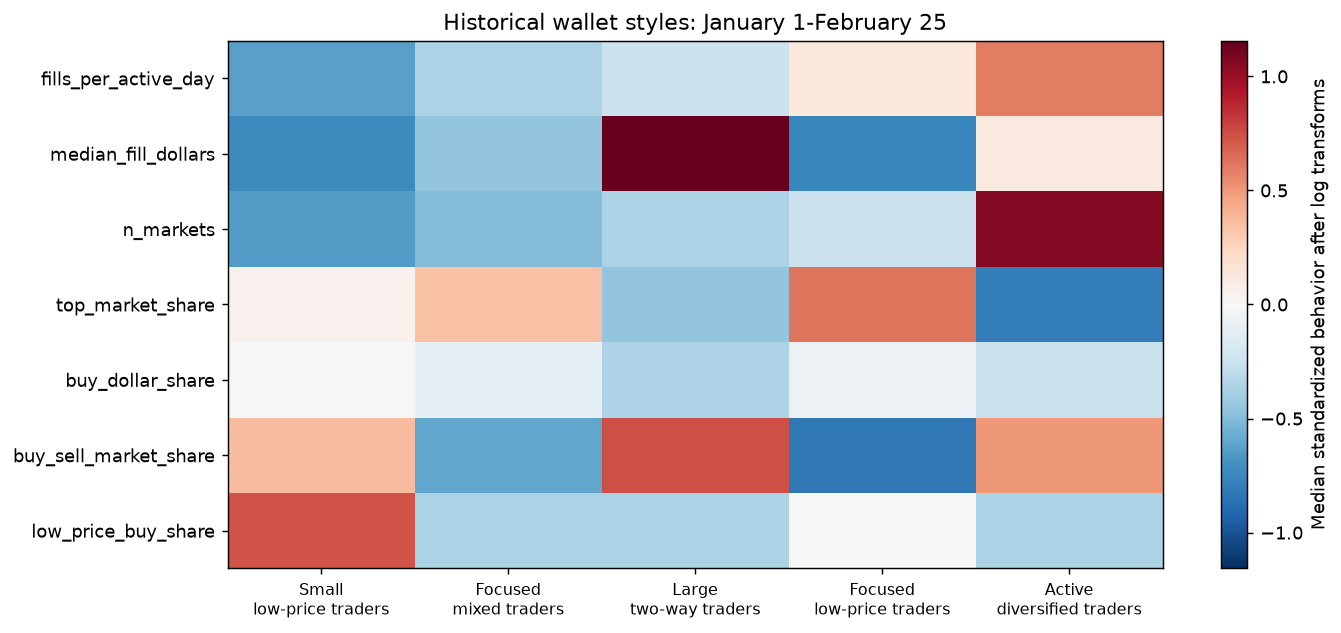

In [18]:
heatmap = pd.DataFrame(X_train, columns=cluster_features).assign(
    style=training_profiles["style"].to_numpy()
).groupby("style").median().T
fig, ax = plt.subplots(figsize=(11, 5))
limit = max(1, np.abs(heatmap.to_numpy()).max())
image = ax.imshow(heatmap, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(5), [style_names[style].replace(" ", "\n", 1) for style in heatmap.columns], fontsize=9)
ax.set_yticks(range(len(cluster_features)), cluster_features)
ax.set_title("Historical wallet styles: January 1-February 25")
fig.colorbar(image, ax=ax, label="Median standardized behavior after log transforms")
plt.tight_layout()
plt.show()

### 4. Follow the original cohort

Apply the frozen model to later eight-week behavior. A missing wallet means no recorded trades in that window, not a verified platform exit. Same-style percentages below use only wallets eligible for profiling again.

The independent later-period refits had ARI 0.302 and 0.214 against frozen assignments. Together with the transitions below, this limits an interpretation as stable identities. Population changes, behavior changes, and collection differences remain possible contributors.

In [19]:
baseline_profiles = training_profiles[["wallet", "style"]].rename(columns={"style": "baseline_style"})
wallet_profiles = profile_data[["wallet", "window", "style"]].copy()
cohort = pd.MultiIndex.from_product(
    [baseline_profiles["wallet"], [1, 2, 3]], names=["wallet", "window"]
).to_frame(index=False)
cohort = cohort.merge(baseline_profiles, on="wallet", how="left", validate="many_to_one")
cohort = cohort.merge(wallet_features[["wallet", "window", "n_fills"]], on=["wallet", "window"], how="left", validate="one_to_one")
cohort = cohort.merge(wallet_profiles, on=["wallet", "window"], how="left", validate="one_to_one")
cohort["status"] = "Insufficient activity"
cohort.loc[cohort["n_fills"].isna(), "status"] = "No recorded trades"
cohort.loc[cohort["style"].notna(), "status"] = "Profiled"
pd.crosstab(cohort["window"], cohort["status"])

status,Insufficient activity,No recorded trades,Profiled
window,,,
1,0,0,39259
2,9096,15606,14557
3,11578,17957,9724


In [20]:
followup_rows = []
for window in [2, 3]:
    group = cohort[cohort["window"].eq(window)]
    paired = group[group["style"].notna()]
    followup_rows.append({
        "window": window, "original_wallets": len(group),
        "wallets_with_records": int(group["n_fills"].notna().sum()),
        "profiled_again": len(paired),
        "same_style_pct_among_profiled": 100 * paired["style"].eq(paired["baseline_style"]).mean(),
    })
profile_followup = pd.DataFrame(followup_rows).set_index("window")
profile_followup.round(2)

,original_wallets,wallets_with_records,profiled_again,same_style_pct_among_profiled
window,,,,
2,39259,23653,14557,52.19
3,39259,21302,9724,40.77


## Settlement Comparison

### 1. Outcome sample and interpretation

Keep each original wallet's **window-1 label** when evaluating its later purchases. Use canonical `['Yes', 'No']` markets with a consistent terminal record before October 21, 2026. Other market labels remain in the profile study.

The recorded close time can fall back to a scheduled date; it is not a verified news timestamp. Exclude purchases at or after that time. Unmatched markets and wallets with no scored purchases are not assigned losses or zero returns.

Score **BUY entries hypothetically held to resolution**, ignoring actual SELLs: winning shares pay 1, losing shares pay 0. This benchmark describes entry outcomes before fees and rewards. It is not realized wallet PnL, full position accounting, or a measure of market-making profitability.

In [21]:
label_cutoff = pd.Timestamp("2026-10-21", tz="UTC")
settled = resolutions[["market_slug", "resolved_yes", "price_at_close", "resolved_at"]].merge(
    markets[["slug", "outcomes"]], left_on="market_slug", right_on="slug", how="inner", validate="one_to_one",
)
settled["resolved_at"] = pd.to_datetime(settled["resolved_at"], utc=True)
settled["price_at_close"] = pd.to_numeric(settled["price_at_close"])
canonical = settled["outcomes"].map(lambda labels: labels == ["Yes", "No"])
terminal = settled["price_at_close"].le(0.01) | settled["price_at_close"].ge(0.99)
consistent = settled["resolved_yes"].eq(settled["price_at_close"].gt(0.5))
settled = settled.loc[
    canonical & terminal & consistent
    & settled["resolved_at"].ge(pd.Timestamp(start_date, tz="UTC"))
    & settled["resolved_at"].lt(label_cutoff)
].copy()
settled["winning_outcome"] = np.where(settled["resolved_yes"], "Yes", "No")

buy_mask = (
    feature_trades["window"].isin([2, 3]) & feature_trades["side"].eq("BUY")
    & feature_trades["wallet"].isin(baseline_profiles["wallet"])
    & feature_trades["size"].gt(0) & feature_trades["dollars"].gt(0)
)
followup_buys = feature_trades.loc[
    buy_mask, ["wallet", "window", "market", "outcome", "time", "size", "dollars"]
].merge(baseline_profiles, on="wallet", how="inner", validate="many_to_one")
matched_buys = followup_buys.merge(
    settled[["market_slug", "resolved_at", "winning_outcome"]],
    left_on="market", right_on="market_slug", how="inner", validate="many_to_one",
)
scored_buys = matched_buys.loc[
    matched_buys["time"].lt(matched_buys["resolved_at"])
    & matched_buys["outcome"].isin(["Yes", "No"])
].copy()
scored_buys["won"] = scored_buys["outcome"].eq(scored_buys["winning_outcome"]).astype("int64")

In [22]:
settlement_coverage = followup_buys.groupby("window").agg(
    wallets_with_positive_buys=("wallet", "nunique"), buy_dollars=("dollars", "sum"),
)
settlement_coverage["scored_wallets"] = scored_buys.groupby("window")["wallet"].nunique()
settlement_coverage["scored_buy_dollars"] = scored_buys.groupby("window")["dollars"].sum()
settlement_coverage["scored_pct_of_original_wallets"] = 100 * settlement_coverage["scored_wallets"] / len(baseline_profiles)
settlement_coverage["scored_pct_of_cohort_buy_dollars"] = 100 * settlement_coverage["scored_buy_dollars"] / settlement_coverage["buy_dollars"]
settlement_coverage.round(2)

,wallets_with_positive_buys,buy_dollars,scored_wallets,scored_buy_dollars,scored_pct_of_original_wallets,scored_pct_of_cohort_buy_dollars
window,,,,,,
2,21270,157663813.36,13879,52856341.81,35.35,33.52
3,19597,225669487.62,14169,88923312.83,36.09,39.4


### 2. Hit rates and hypothetical returns

Aggregate once per wallet × market × outcome × window. This avoids counting split fills as independent wins. Buying both outcomes produces one entry for each side; hit rate alone does not measure skill.

Mean wallet hit rate and entry-price reference weight wallets equally. Pooled hypothetical ROI weights by BUY dollars; median wallet ROI describes a different, typical-wallet perspective.

In [23]:
entry_results = scored_buys.groupby(
    ["window", "baseline_style", "wallet", "market", "outcome"], as_index=False
).agg(
    buy_shares=("size", "sum"), buy_dollars=("dollars", "sum"), won=("won", "first"),
)
entry_results["avg_entry_price"] = entry_results["buy_dollars"] / entry_results["buy_shares"]
entry_results["hypothetical_profit"] = entry_results["buy_shares"] * entry_results["won"] - entry_results["buy_dollars"]

wallet_outcomes = entry_results.groupby(["window", "baseline_style", "wallet"], as_index=False).agg(
    settled_markets=("market", "nunique"), hit_rate=("won", "mean"),
    entry_price_reference=("avg_entry_price", "mean"),
    buy_dollars=("buy_dollars", "sum"), hypothetical_profit=("hypothetical_profit", "sum"),
)
wallet_outcomes["hypothetical_roi"] = wallet_outcomes["hypothetical_profit"] / wallet_outcomes["buy_dollars"]
performance = wallet_outcomes.groupby(["window", "baseline_style"]).agg(
    scored_wallets=("wallet", "size"), mean_wallet_hit_rate=("hit_rate", "mean"),
    mean_wallet_entry_price=("entry_price_reference", "mean"),
    median_wallet_roi=("hypothetical_roi", "median"),
    buy_dollars=("buy_dollars", "sum"), hypothetical_profit=("hypothetical_profit", "sum"),
)
performance["pooled_hypothetical_roi"] = performance["hypothetical_profit"] / performance["buy_dollars"]
baseline_counts = baseline_profiles["baseline_style"].value_counts()
performance["scored_pct_of_original_style"] = 100 * performance["scored_wallets"] / performance.index.get_level_values("baseline_style").map(baseline_counts)

outcome_summary = performance[[
    "scored_wallets", "scored_pct_of_original_style", "mean_wallet_entry_price", "mean_wallet_hit_rate",
    "median_wallet_roi", "pooled_hypothetical_roi",
]].copy()
for column in ["mean_wallet_entry_price", "mean_wallet_hit_rate", "median_wallet_roi", "pooled_hypothetical_roi"]:
    outcome_summary[column] = 100 * outcome_summary[column]
outcome_summary = outcome_summary.rename(columns={
    "scored_wallets": "Scored wallets", "scored_pct_of_original_style": "Original style covered (%)",
    "mean_wallet_entry_price": "Entry reference (%)", "mean_wallet_hit_rate": "Hit rate (%)",
    "median_wallet_roi": "Median wallet ROI (%)", "pooled_hypothetical_roi": "Pooled ROI (%)",
})
outcome_summary.round(2)

Scored wallets  ...  Pooled ROI (%)
window baseline_style                  ...                
2      Style 1                   1320  ...           -0.46
       Style 2                   3365  ...           -3.75
       Style 3                   2559  ...            0.01
       Style 4                   1847  ...           -3.01
       Style 5                   4788  ...           -0.54
3      Style 1                   1619  ...           -4.12
       Style 2                   3535  ...            7.06
       Style 3                   2838  ...             0.7
       Style 4                   1832  ...            6.51
       Style 5                   4345  ...            2.35

[10 rows x 6 columns]

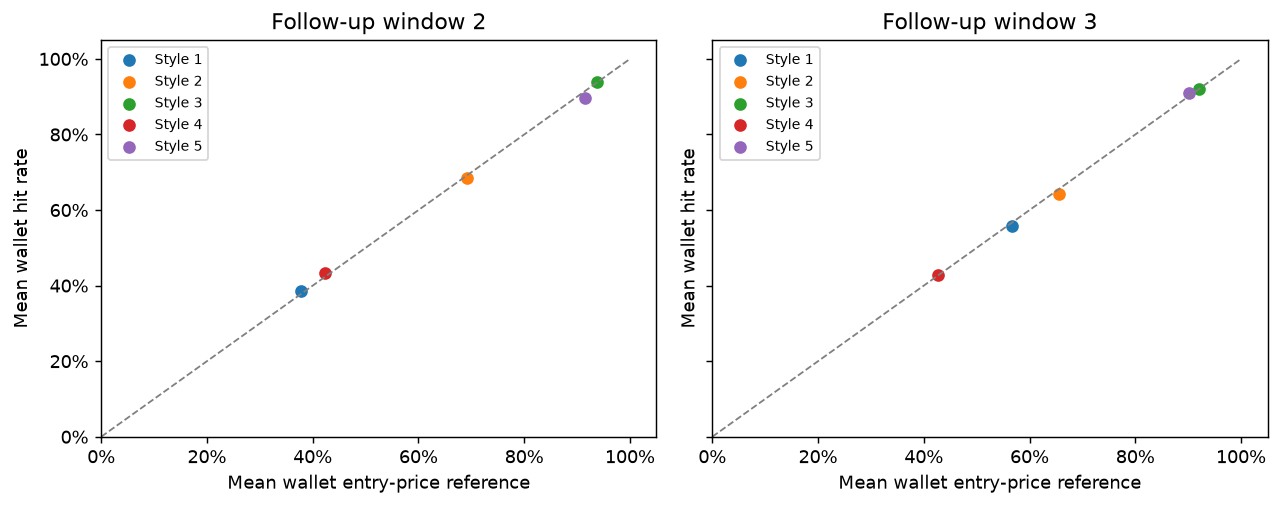

In [24]:
styles = list(style_names)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, window in zip(axes, [2, 3]):
    values = performance.loc[window].reindex(styles)
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
    for style, row in values.iterrows():
        ax.scatter(row["mean_wallet_entry_price"], row["mean_wallet_hit_rate"], label=style)
    ax.set(xlim=(0, 1.05), ylim=(0, 1.05), xlabel="Mean wallet entry-price reference", ylabel="Mean wallet hit rate", title=f"Follow-up window {window}")
    ax.legend(loc="upper left", fontsize=8)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

### 3. Pooled results versus the typical wallet

High hit rates can follow from buying high-priced contracts. Entry prices are descriptive probability references, not a guarantee of calibration. Positive pooled returns can also coexist with a negative median wallet return; neither figure should stand in for the other.

The independent validation includes event-block intervals, price-band comparisons, and sensitivity samples. It found no group with a wholly positive pooled-return interval in both follow-ups. These observed point estimates do not establish a reliably profitable trader type.

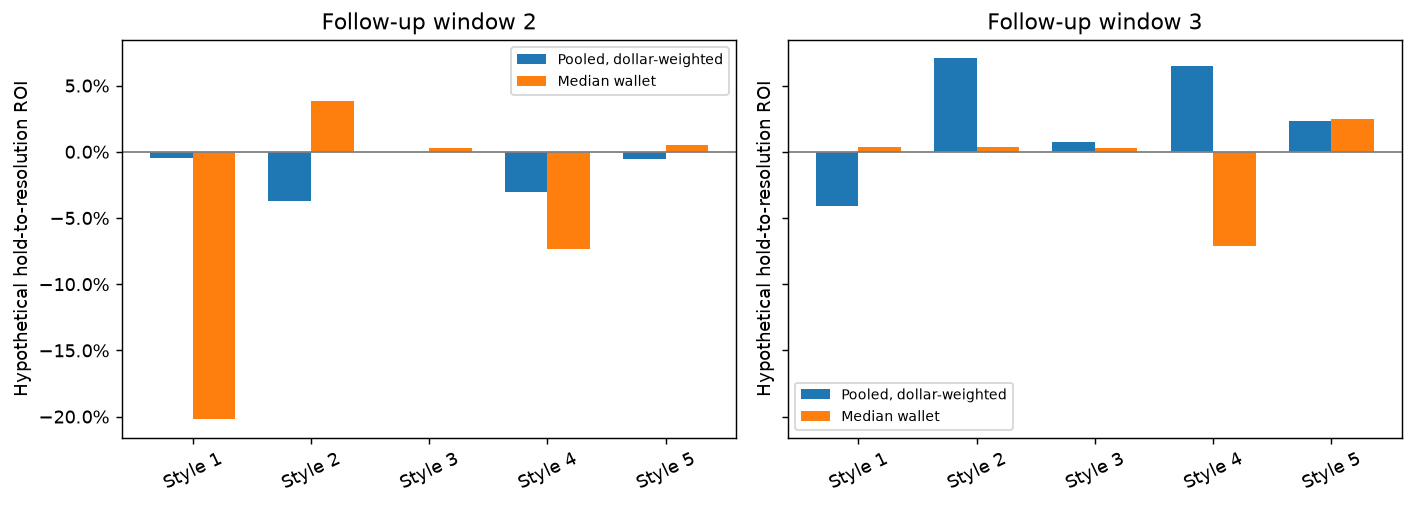

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
x = np.arange(len(styles))
for ax, window in zip(axes, [2, 3]):
    values = performance.loc[window].reindex(styles)
    ax.bar(x - 0.18, values["pooled_hypothetical_roi"], width=0.36, label="Pooled, dollar-weighted")
    ax.bar(x + 0.18, values["median_wallet_roi"], width=0.36, label="Median wallet")
    ax.axhline(0, color="grey", linewidth=1)
    ax.set_xticks(x, styles, rotation=25)
    ax.set_title(f"Follow-up window {window}")
    ax.set_ylabel("Hypothetical hold-to-resolution ROI")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4. The last four weeks separately

The final four weeks contain 39.93 million fills, versus 3.97 million in the preceding four weeks. This observed coverage/composition change has an unresolved cause. Keep the original profiles and split only the later purchases below.

In [26]:
late_buys = scored_buys.loc[scored_buys["window"].eq(3)].copy()
late_buys["half"] = np.where(
    late_buys["time"].lt(pd.Timestamp("2026-05-21", tz="UTC")), "Apr 23-May 20", "May 21-Jun 17"
)
late_buys["hypothetical_profit"] = late_buys["size"] * late_buys["won"] - late_buys["dollars"]
late_comparison = late_buys.groupby(["baseline_style", "half"]).agg(
    buy_dollars=("dollars", "sum"), hypothetical_profit=("hypothetical_profit", "sum"),
)
late_comparison["pooled_roi_pct"] = 100 * late_comparison["hypothetical_profit"] / late_comparison["buy_dollars"]
late_comparison["pooled_roi_pct"].unstack("half").round(2)

half,Apr 23-May 20,May 21-Jun 17
baseline_style,,
Style 1,0.75,-5.28
Style 2,-2.5,10.29
Style 3,0.8,0.55
Style 4,3.44,7.73
Style 5,0.41,5.14


## Findings

- The five profiles describe historical trading states. Training resampling was strong, but cross-window reproducibility was limited; these are not fixed user identities.
- **Winning often is not the same as earning a high return.** Style 3's mean wallet hit rate is 93.78% and 92.06% in the follow-ups, close to its entry-price references. Its pooled hypothetical ROI is only +0.01% and +0.70%.
- **The typical wallet can differ from the pooled result.** Style 4's second-follow-up pooled hypothetical ROI is +6.51%, while its median wallet ROI is −7.15%.
- Economic ordering changes across time, and the outcome sample covers only recorded, qualifying Yes/No purchases with available labels. Later purchases have less time to resolve before the common cutoff. Missing outcomes are not losses, and the comparisons are observational rather than causal.

The supported interpretation is a descriptive study of trading styles, changes over time, and entry-price/settlement outcomes. It does not establish insider detection, actual wallet PnL, or a consistently superior trading group.

Full model comparison and checks remain in [wallet_style_settlement_validation.ipynb](wallet_style_settlement_validation.ipynb).